# COM7022 Machine Learning

## Task 1 Practical Project



## Dataset Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

data = pd.read_csv("Sales-[5444].csv")

print("Dataset shape:", data.shape)
display(data.head())


Dataset shape: (1000, 10)


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


## Dataset Information

In [2]:
print(data.info())
print("\\nMissing values:")
display(data.isnull().sum().to_frame("Missing values"))
print("\\nDuplicate rows:", data.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    object 
 1   details            1000 non-null   object 
 2   Catatory           997 non-null    object 
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    object 
 5   available          889 non-null    float64
 6   text               997 non-null    object 
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    object 
 9   itemLocation       1000 non-null   object 
dtypes: float64(3), object(7)
memory usage: 78.3+ KB
None
\nMissing values:


,Missing values
Item_Name,1
details,0
Catatory,3
price,5
priceWithCurrency,1
available,111
text,3
sold,8
lastUpdated,53
itemLocation,0


\nDuplicate rows: 0


## Data Exploration

,price,available,sold
count,995.000000,889.000000,992.000000
mean,46.433467,20.046119,775.246976
std,35.551712,61.547985,3211.433298
min,3.000000,2.000000,1.000000
25%,22.990000,5.000000,14.000000
50%,35.710000,10.000000,49.500000
75%,59.000000,10.000000,324.750000
max,259.090000,842.000000,54052.000000


Number of product categories: 63
Most common categories:


,Product count
Catatory,
Eau de Toilette,444
Eau de Parfum,285
Eau de Cologne,56
Perfume,50
Fragrances,32
Eau De Parfum,15
Parfum,13
Eau de Perfume,10
Eau De Toilette,9


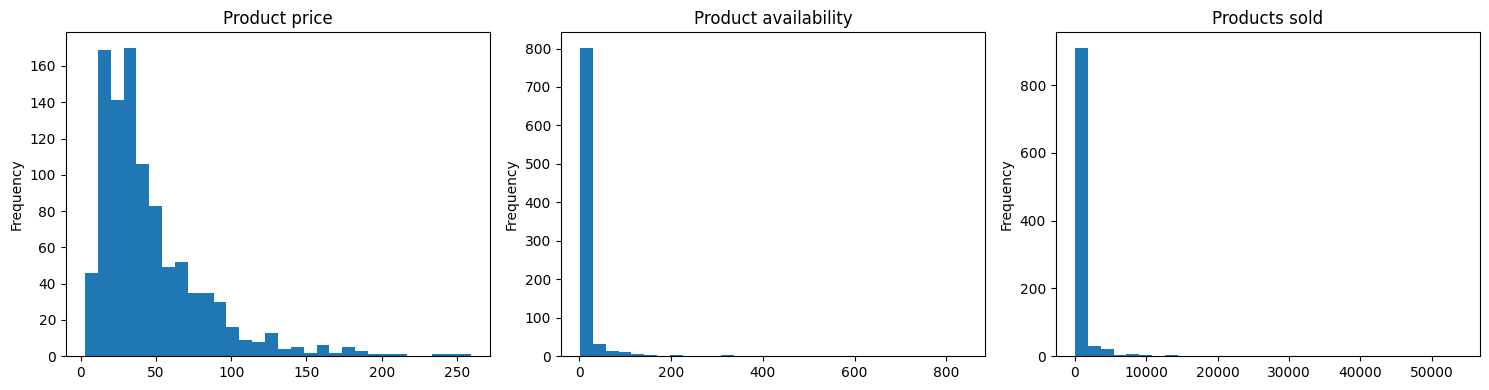

In [3]:
display(data[["price", "available", "sold"]].describe())
print("Number of product categories:", data["Catatory"].nunique())
print("Most common categories:")
display(data["Catatory"].value_counts().head(10).to_frame("Product count"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data["price"].plot(kind="hist", bins=30, ax=axes[0], title="Product price")
data["available"].plot(kind="hist", bins=30, ax=axes[1], title="Product availability")
data["sold"].plot(kind="hist", bins=30, ax=axes[2], title="Products sold")
plt.tight_layout()
plt.show()


## Feature Selection

In [4]:
selected_features = ["price", "available", "sold", "Catatory"]
analysis_data = data[selected_features].copy()

print("Selected features:")
display(analysis_data.head())

print("The analysis uses price, available stock, units sold and product category. These fields represent product value, current stock, sales performance and product type. The item description, currency text, availability text, update date and item location are not used because they are either descriptive, duplicate information, high-cardinality fields or not directly needed for this product grouping analysis.")


Selected features:


,price,available,sold,Catatory
0,84.99,10.0,NaN,Eau de Parfum
1,NaN,8.0,48.0,Eau de Parfum
2,100.00,10.0,27.0,Eau de Toilette
3,NaN,2.0,159.0,Eau de Toilette
4,16.91,NaN,NaN,Fragrances


The analysis uses price, available stock, units sold and product category. These fields represent product value, current stock, sales performance and product type. The item description, currency text, availability text, update date and item location are not used because they are either descriptive, duplicate information, high-cardinality fields or not directly needed for this product grouping analysis.


## Data Cleaning

In [5]:
analysis_data["price"] = pd.to_numeric(analysis_data["price"], errors="coerce")
analysis_data["available"] = pd.to_numeric(analysis_data["available"], errors="coerce")
analysis_data["sold"] = pd.to_numeric(analysis_data["sold"], errors="coerce")

numeric_features = ["price", "available", "sold"]

for column in numeric_features:
    analysis_data[column] = analysis_data[column].fillna(analysis_data[column].median())

analysis_data["Catatory"] = analysis_data["Catatory"].fillna("Unknown")
analysis_data["Catatory"] = analysis_data["Catatory"].replace("", "Unknown")

print("Missing values after treatment:")
display(analysis_data.isnull().sum().to_frame("Missing values"))
display(analysis_data.head())


Missing values after treatment:


,Missing values
price,0
available,0
sold,0
Catatory,0


,price,available,sold,Catatory
0,84.99,10.0,49.5,Eau de Parfum
1,35.71,8.0,48.0,Eau de Parfum
2,100.00,10.0,27.0,Eau de Toilette
3,35.71,2.0,159.0,Eau de Toilette
4,16.91,10.0,49.5,Fragrances


## Data Transformation

In [6]:
analysis_data[numeric_features] = np.log1p(analysis_data[numeric_features])

category_data = pd.get_dummies(analysis_data["Catatory"], prefix="category", dtype=int)
model_data = pd.concat([analysis_data[numeric_features], category_data], axis=1)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(model_data)

print("Model data shape:", model_data.shape)
print("Scaled data shape:", scaled_data.shape)
print("All transformed values are finite:", np.isfinite(scaled_data).all())


Model data shape: (1000, 67)
Scaled data shape: (1000, 67)
All transformed values are finite: True


## K-means clustering

In [7]:
kmeans_results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_data)
    kmeans_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(scaled_data, labels),
        "Davies-Bouldin Score": davies_bouldin_score(scaled_data, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(scaled_data, labels),
        "Inertia": model.inertia_
    })

kmeans_results = pd.DataFrame(kmeans_results)
display(kmeans_results.round(4))

best_k = int(kmeans_results.loc[kmeans_results["Silhouette Score"].idxmax(), "Clusters"])
kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(scaled_data)

print("Selected number of clusters:", best_k)
print("Cluster sizes:")
display(pd.Series(kmeans_labels).value_counts().sort_index().to_frame("Products"))


,Clusters,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Inertia
0,2,0.1328,3.3287,25.4893,65331.4140
1,3,0.1434,2.6368,21.2665,64258.6596
2,4,0.1732,2.7525,20.0491,63184.3650
3,5,0.1636,1.8946,19.3573,62162.6132
4,6,0.2286,2.6082,19.3678,61052.0820
5,7,0.2435,2.5743,19.3827,59975.8516
6,8,0.1698,1.1855,18.6316,59214.8346


Selected number of clusters: 7
Cluster sizes:


,Products
0,188
1,456
2,10
3,56
4,288
5,1
6,1


## Hierarchical clustering

In [8]:
hierarchical_results = []

for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(scaled_data)
    hierarchical_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(scaled_data, labels),
        "Davies-Bouldin Score": davies_bouldin_score(scaled_data, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(scaled_data, labels)
    })

hierarchical_results = pd.DataFrame(hierarchical_results)
display(hierarchical_results.round(4))

best_hierarchical_k = int(hierarchical_results.loc[hierarchical_results["Silhouette Score"].idxmax(), "Clusters"])
hierarchical_model = AgglomerativeClustering(n_clusters=best_hierarchical_k, linkage="ward")
hierarchical_labels = hierarchical_model.fit_predict(scaled_data)

print("Selected number of clusters:", best_hierarchical_k)
print("Cluster sizes:")
display(pd.Series(hierarchical_labels).value_counts().sort_index().to_frame("Products"))


,Clusters,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,2,0.1234,3.2321,25.2083
1,3,0.2230,4.5161,22.5126
2,4,0.2312,4.8918,21.0809
3,5,0.2638,4.5410,20.3584
4,6,0.2903,4.0339,20.0079
5,7,0.3283,4.0825,19.8697
6,8,0.3828,4.4440,19.8206


Selected number of clusters: 8
Cluster sizes:


,Products
0,89
1,32
2,285
3,444
4,12
5,56
6,32
7,50


## DBSCAN clustering

In [9]:
dbscan_results = []

for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0]:
    for min_samples in [5, 10]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(scaled_data)
        cluster_labels = set(labels) - {-1}
        number_of_clusters = len(cluster_labels)
        noise_percentage = (labels == -1).mean() * 100

        if number_of_clusters >= 2:
            non_noise = labels != -1
            score = silhouette_score(scaled_data[non_noise], labels[non_noise])
            db_score = davies_bouldin_score(scaled_data[non_noise], labels[non_noise])
            ch_score = calinski_harabasz_score(scaled_data[non_noise], labels[non_noise])
        else:
            score = np.nan
            db_score = np.nan
            ch_score = np.nan

        dbscan_results.append({
            "Epsilon": eps,
            "Minimum samples": min_samples,
            "Clusters": number_of_clusters,
            "Noise percentage": noise_percentage,
            "Silhouette Score": score,
            "Davies-Bouldin Score": db_score,
            "Calinski-Harabasz Score": ch_score
        })

dbscan_results = pd.DataFrame(dbscan_results)
display(dbscan_results.round(4))

valid_dbscan = dbscan_results.dropna(subset=["Silhouette Score"])

if len(valid_dbscan) > 0:
    best_dbscan_row = valid_dbscan.loc[valid_dbscan["Silhouette Score"].idxmax()]
    best_eps = float(best_dbscan_row["Epsilon"])
    best_min_samples = int(best_dbscan_row["Minimum samples"])
    dbscan_model = DBSCAN(eps=best_eps, min_samples=best_min_samples)
    dbscan_labels = dbscan_model.fit_predict(scaled_data)
    print("Selected epsilon:", best_eps)
    print("Selected minimum samples:", best_min_samples)
    print("Cluster sizes, including noise (-1):")
    display(pd.Series(dbscan_labels).value_counts().sort_index().to_frame("Products"))
else:
    best_eps = None
    best_min_samples = None
    dbscan_labels = np.full(len(scaled_data), -1)
    print("DBSCAN did not identify at least two clusters for the tested settings.")


,Epsilon,Minimum samples,Clusters,Noise percentage,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,1.5,5,11,9.6,0.4606,0.4883,377.2621
1,1.5,10,6,13.8,0.4983,0.6188,438.7589
2,2.0,5,10,8.3,0.5041,0.4823,414.0847
3,2.0,10,7,11.5,0.4974,0.5772,436.4670
4,2.5,5,11,7.5,0.5054,0.4601,407.5339
5,2.5,10,8,9.6,0.4970,0.5559,416.0846
6,3.0,5,10,7.5,0.5137,0.4756,230.9911
7,3.0,10,7,9.5,0.5056,0.5717,232.1865
8,3.5,5,10,7.5,0.5137,0.4756,230.9911
9,3.5,10,7,9.5,0.5056,0.5717,232.1865


Selected epsilon: 3.0
Selected minimum samples: 5
Cluster sizes, including noise (-1):


,Products
-1,75
0,729
1,32
2,50
3,13
4,15
5,56
6,9
7,10
8,6


## Model Comparison

In [10]:
comparison_rows = []

comparison_rows.append({
    "Model": "K-means",
    "Clusters": len(set(kmeans_labels)),
    "Silhouette Score": silhouette_score(scaled_data, kmeans_labels),
    "Davies-Bouldin Score": davies_bouldin_score(scaled_data, kmeans_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(scaled_data, kmeans_labels),
    "Noise percentage": 0.0
})

comparison_rows.append({
    "Model": "Hierarchical",
    "Clusters": len(set(hierarchical_labels)),
    "Silhouette Score": silhouette_score(scaled_data, hierarchical_labels),
    "Davies-Bouldin Score": davies_bouldin_score(scaled_data, hierarchical_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(scaled_data, hierarchical_labels),
    "Noise percentage": 0.0
})

if best_eps is not None:
    non_noise = dbscan_labels != -1
    db_clusters = len(set(dbscan_labels) - {-1})
    if db_clusters >= 2 and non_noise.sum() > db_clusters:
        db_silhouette = silhouette_score(scaled_data[non_noise], dbscan_labels[non_noise])
        db_davies = davies_bouldin_score(scaled_data[non_noise], dbscan_labels[non_noise])
        db_calinski = calinski_harabasz_score(scaled_data[non_noise], dbscan_labels[non_noise])
    else:
        db_silhouette = np.nan
        db_davies = np.nan
        db_calinski = np.nan

    comparison_rows.append({
        "Model": "DBSCAN",
        "Clusters": db_clusters,
        "Silhouette Score": db_silhouette,
        "Davies-Bouldin Score": db_davies,
        "Calinski-Harabasz Score": db_calinski,
        "Noise percentage": (dbscan_labels == -1).mean() * 100
    })

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.round(4))


,Model,Clusters,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Noise percentage
0,K-means,7,0.2435,2.5743,19.3827,0.0
1,Hierarchical,8,0.3828,4.4440,19.8206,0.0
2,DBSCAN,10,0.5137,0.4756,230.9911,7.5


## PCA

Explained variance by first component: 0.0307
Explained variance by second component: 0.0207
Total explained variance: 0.0513


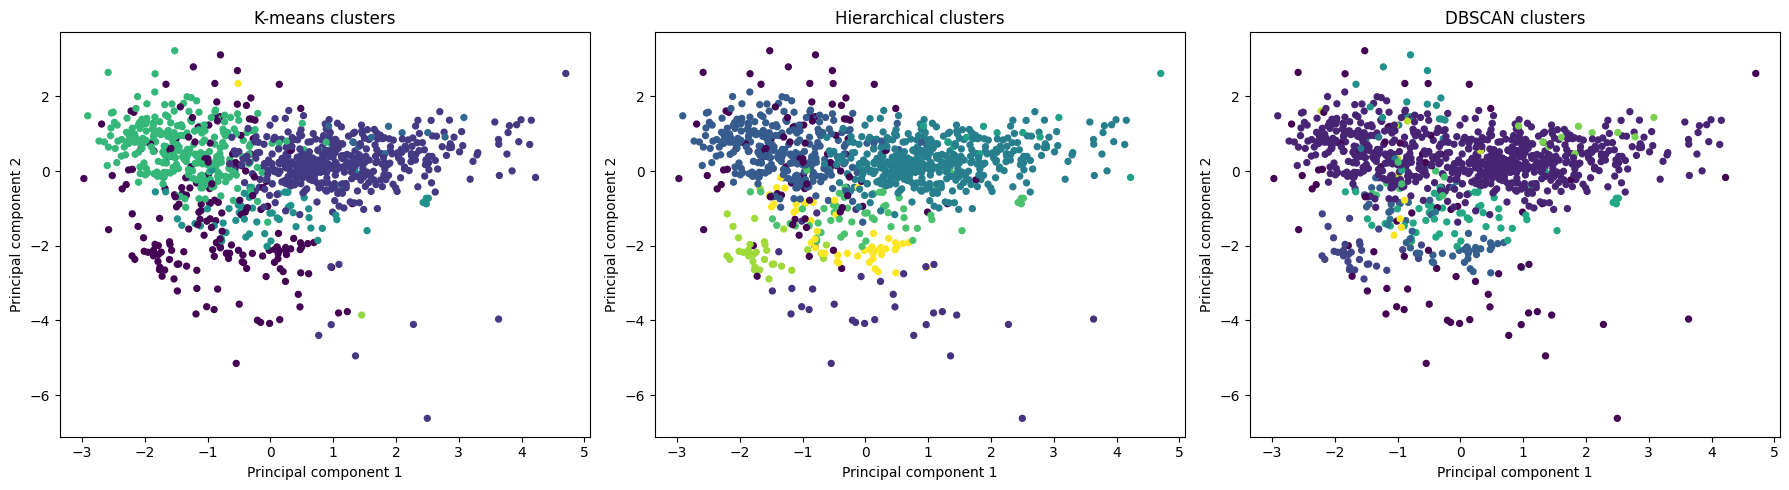

In [11]:
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

print("Explained variance by first component:", round(pca.explained_variance_ratio_[0], 4))
print("Explained variance by second component:", round(pca.explained_variance_ratio_[1], 4))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(pca_data[:, 0], pca_data[:, 1], c=kmeans_labels, cmap="viridis", s=18)
axes[0].set_title("K-means clusters")
axes[0].set_xlabel("Principal component 1")
axes[0].set_ylabel("Principal component 2")

axes[1].scatter(pca_data[:, 0], pca_data[:, 1], c=hierarchical_labels, cmap="viridis", s=18)
axes[1].set_title("Hierarchical clusters")
axes[1].set_xlabel("Principal component 1")
axes[1].set_ylabel("Principal component 2")

axes[2].scatter(pca_data[:, 0], pca_data[:, 1], c=dbscan_labels, cmap="viridis", s=18)
axes[2].set_title("DBSCAN clusters")
axes[2].set_xlabel("Principal component 1")
axes[2].set_ylabel("Principal component 2")

plt.tight_layout()
plt.show()


## Cluster Analysis

In [12]:
cluster_data = analysis_data.copy()
cluster_data["Hierarchical_Cluster"] = hierarchical_labels

hierarchical_profile = cluster_data.groupby("Hierarchical_Cluster").agg(
    Product_Count=("price", "size"),
    Average_Price=("price", "mean"),
    Average_Available=("available", "mean"),
    Average_Sold=("sold", "mean")
).round(2)

display(hierarchical_profile)

category_profile = cluster_data.groupby(["Hierarchical_Cluster", "Catatory"]).size().unstack(fill_value=0)
display(category_profile)


,Product_Count,Average_Price,Average_Available,Average_Sold
Hierarchical_Cluster,,,,
0,89,3.97,2.07,3.76
1,32,2.70,2.20,3.94
2,285,3.84,2.15,3.67
3,444,3.57,2.46,4.93
4,12,3.53,3.89,6.22
5,56,3.43,2.34,4.45
6,32,3.45,1.54,2.77
7,50,3.34,2.24,3.77


Catatory,/,Aftershave,Assorted,Body Oil,Body Spray,Car Air Freshener,Cologne,Cologne spray,Concentrated Uncut Pure Body Oil,DIOR HOMME COLOGNE,De Nuit,Deodorant,Deodorant Body Spray,Does not apply,EAU DE COLOGNE SPRAY,EDC,EDT,EXTRAIT DE PARFUM,Eau De Cologne,Eau De Parfum,Eau De Parfum Intense,Eau De Toilette,"Eau De Toilette, Eau De Parfum, Eau De Parfum Intense",Eau de Cologne,"Eau de Cologne Spray, Cologne Spray",Eau de Parfum,Eau de Parfum Intense,Eau de Parfum/ Eau de Toilette,Eau de Perfume,Eau de Toilette,Eau de Toilette Intense,"Eau de Toilette, Cologne Spray",Eau de Toillette,Eau de toilette,Editions Parfums,Elixir,Elixir de Parfum,Extrait De Parfum,Extrait de Parfum,Fine Cologne,Fragrance & Perfume,Fragrance Body Spray,Fragrance Oil,Fragrance Rolling Ball,Fragrances,Gift Sets,Jo Malone Cologne Intense Spray,LE PARFUM,Oil,PARFUM,Parfum,Parfum Intense,Perfume,Pheromone,Roll On,Splash-on,Unknown,Unscented,Various,Y,cologne,edt,le parfum,~ THE ONE EAU DE PARFUM SPRAY ~
Hierarchical_Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,3,0,0,0,0,5,0,0,1,1,0,1,3,0,1,3,1,0,15,0,9,0,0,0,0,1,0,0,0,1,0,1,1,0,1,0,1,1,1,1,0,0,0,0,6,1,2,0,4,13,3,0,0,0,0,3,1,0,1,0,1,1,1
1,3,0,1,1,4,1,0,1,1,0,0,1,0,0,1,0,0,0,1,0,2,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,1,2,0,0,0,0,1,0,0,0,0,2,1,1,0,0,1,0,1,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,285,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,444,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,10,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,56,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,32,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,50,0,0,0,0,0,0,0,0,0,0,0


## Final Model Selection

In [13]:
print("Model comparison:")
display(model_comparison.round(4))

print("The highest silhouette score is produced by DBSCAN. However, this score is calculated after excluding noise records. DBSCAN labels 7.5% of products as noise and places 729 products in one cluster, while several other clusters are very small.")

print("K-means produces two clusters containing only one product each. This limits its usefulness for practical product segmentation.")

print("Hierarchical clustering is selected as the final model for this business task. It assigns every product to a cluster, avoids noise records and produces eight groups with a minimum cluster size of 12 products. Its silhouette score is 0.3828. Although DBSCAN has a higher silhouette score, the hierarchical result offers a more useful balance between separation, coverage and cluster size for business interpretation.")

print("\\nSelected model: Hierarchical clustering")
print("Number of clusters:", best_hierarchical_k)
print("Cluster sizes:")
display(pd.Series(hierarchical_labels).value_counts().sort_index().to_frame("Products"))

print("\\nBusiness interpretation:")
print("The hierarchical cluster profile reports average price, stock availability and sales for each product group. Groups with higher average sales may need stock continuity. Groups with high stock and lower sales may require a review of purchasing levels or promotional activity. Higher-priced groups may need separate pricing and marketing decisions.")


Model comparison:


,Model,Clusters,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Noise percentage
0,K-means,7,0.2435,2.5743,19.3827,0.0
1,Hierarchical,8,0.3828,4.4440,19.8206,0.0
2,DBSCAN,10,0.5137,0.4756,230.9911,7.5


The highest silhouette score is produced by DBSCAN. However, this score is calculated after excluding noise records. DBSCAN labels 7.5% of products as noise and places 729 products in one cluster, while several other clusters are very small.
K-means produces two clusters containing only one product each. This limits its usefulness for practical product segmentation.
Hierarchical clustering is selected as the final model for this business task. It assigns every product to a cluster, avoids noise records and produces eight groups with a minimum cluster size of 12 products. Its silhouette score is 0.3828. Although DBSCAN has a higher silhouette score, the hierarchical result offers a more useful balance between separation, coverage and cluster size for business interpretation.
\nSelected model: Hierarchical clustering
Number of clusters: 8
Cluster sizes:


,Products
0,89
1,32
2,285
3,444
4,12
5,56
6,32
7,50


\nBusiness interpretation:
The hierarchical cluster profile reports average price, stock availability and sales for each product group. Groups with higher average sales may need stock continuity. Groups with high stock and lower sales may require a review of purchasing levels or promotional activity. Higher-priced groups may need separate pricing and marketing decisions.
